In [ ]:
import pandas as pd
import csv
from google.colab import files

# List of selected file paths
file_paths = [
    '/content/YouTube_Live_1.csv',
    '/content/YouTube_Live_2.csv',
    '/content/YouTube_Live_3.csv',
    '/content/YouTube_Live_4.csv',
    '/content/YouTube_Live_5.csv'
]

# Load and concatenate all datasets with relaxed quoting rules to handle parsing anomalies
dataframes = []
for path in file_paths:
    try:
        # using quoting=csv.QUOTE_NONE and on_bad_lines='skip' to ensure robust parsing
        df = pd.read_csv(path, quoting=csv.QUOTE_NONE, on_bad_lines='skip')
        df['source_file'] = path.split('/')[-1]
        dataframes.append(df)
        print(f"Successfully loaded: {path} with {len(df)} rows.")
    except Exception as e:
        print(f"Error loading {path}: {e}")

if dataframes:
    merged_df = pd.concat(dataframes, ignore_index=True)
    output_path = '/content/YouTube_Live_Merged.csv'
    merged_df.to_csv(output_path, index=False)
    print(f"\nTotal rows in merged dataset: {len(merged_df)}")
    print(f"Saved merged dataset to {output_path}. Initializing download...")
    files.download(output_path)
else:
    print("No datasets were successfully loaded.")

Successfully loaded: /content/YouTube_Live_1.csv with 79726 rows.
Successfully loaded: /content/YouTube_Live_2.csv with 80123 rows.
Successfully loaded: /content/YouTube_Live_3.csv with 79435 rows.
Successfully loaded: /content/YouTube_Live_4.csv with 65155 rows.
Successfully loaded: /content/YouTube_Live_5.csv with 81283 rows.

Total rows in merged dataset: 385722
Saved merged dataset to /content/YouTube_Live_Merged.csv. Initializing download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
if 'merged_df' in locals():
    display(merged_df.head())

,No.,Time,Source,Destination,Protocol,Length,Info,source_file
0,87,2022-05-30 08:25:18.220269,10.215.173.1,142.251.72.7,GQUIC,1278.0,"Client Hello, PKN: 1, CID: 4472406183105229454",YouTube_Live_1.csv
1,88,2022-05-30 08:25:18.222899,10.215.173.1,142.251.72.7,GQUIC,936.0,"Payload (Encrypted), PKN: 2, CID: 447240618310...",YouTube_Live_1.csv
2,89,2022-05-30 08:25:18.222949,10.215.173.1,142.251.72.7,GQUIC,817.0,"Payload (Encrypted), PKN: 3, CID: 447240618310...",YouTube_Live_1.csv
3,90,2022-05-30 08:25:18.222975,10.215.173.1,142.251.72.7,GQUIC,931.0,"Payload (Encrypted), PKN: 4, CID: 447240618310...",YouTube_Live_1.csv
4,91,2022-05-30 08:25:18.222994,10.215.173.1,142.251.72.7,GQUIC,931.0,"Payload (Encrypted), PKN: 5, CID: 447240618310...",YouTube_Live_1.csv


**Reasoning**:
Install python-docx and write a Python script to extract and print the complete text from the DOCX file '/content/Project 1 for ML.docx' to understand all project requirements.



In [4]:
!pip install python-docx

import docx

def read_docx(file_path):
    doc = docx.Document(file_path)
    full_text = []
    for para in doc.paragraphs:
        if para.text.strip():
            full_text.append(para.text)

    # Also try to retrieve text from tables if there are any
    for table in doc.tables:
        for row in table.rows:
            row_text = [cell.text.strip() for cell in row.cells if cell.text.strip()]
            if row_text:
                full_text.append(" | ".join(row_text))

    return '\n'.join(full_text)

document_content = read_docx('/content/Project 1 for ML.docx')
print("=== EXTRACTED PROJECT GUIDELINES ===\n")
print(document_content)

=== EXTRACTED PROJECT GUIDELINES ===

 Project 1 into a complete beginner ML project:
Network Protocol Classification Using Machine Learning
Goal: Given network-packet information, predict the Protocol such as TCP, UDP, DNS, etc.
We will use a simple ML workflow:
KT_GameBox Dataset
        ↓
Load Dataset
        ↓
Understand Data
        ↓
Clean Data
        ↓
Feature Engineering
        ↓
Exploratory Data Analysis
        ↓
Select Features
        ↓
Encode Categorical Data
        ↓
Train/Test Split
        ↓
Train ML Models
        ↓
Prediction
        ↓
Accuracy
        ↓
Confusion Matrix
        ↓
Compare Models
        ↓
Predict New Packet
Because your dataset is very large, we'll initially use 100,000 rows. Once the students understand the project, they can increase it.
Step 1 — Install libraries
If using Google Colab, run:
!pip install pandas numpy matplotlib seaborn scikit-learn
If using Anaconda/Jupyter, usually these are already installed.
Then import:
import pandas as pd
imp

# Task
Extract and parse the project guidelines and requirements from the instructor's document "/content/Project 1 for ML.docx", and design a step-by-step project workflow and machine learning plan utilizing the merged dataset "/content/YouTube_Live_Merged.csv".

## Extract Guidelines from DOCX

### Subtask:
Read and parse the contents of 'Project 1 for ML.docx' to fully understand the project requirements, criteria, and expected workflow specified by the instructor.


## Design Project Workflow and Finalize Plan

### Subtask:
Summarize the precise ML tasks, features, targets, and evaluation metrics using the extracted instructions and merged dataset columns.


## Summary:

### Q&A

* **What are the precise machine learning tasks, features, targets, and evaluation metrics required for the project?**
  * **Machine Learning Task**: Network Protocol Classification (predicting network protocols such as TCP, UDP, and DNS from packet information).
  * **Dataset & Features**: The merged dataset (`YouTube_Live_Merged.csv`) contains columns such as `No.`, `Time` (to be engineered into time components like hour, minute, second), `Source`, `Destination`, `Length`, and `Info`.
  * **Target Variable**: `Protocol` (to be encoded using `LabelEncoder`).
  * **Evaluation Metrics**: Models will be evaluated using standard classification metrics including confusion matrices, classification reports (precision, recall, F1-score), and feature importance plots.
  * **Candidate Models**: Logistic Regression, Decision Trees, K-Nearest Neighbors, and Random Forest.

---

### Data Analysis Key Findings

* **Document Structure & Extraction**: Successfully installed `python-docx` and extracted both textual paragraphs and tabular data from the instructor's project guidelines.
* **Target Dataset**: The project is designed to utilize a merged dataset (`YouTube_Live_Merged.csv`) containing key network packet attributes.
* **Feature Engineering Plan**: The raw `Time` timestamp column needs to be decomposed into numerical components (hours, minutes, seconds) to serve as predictive features.
* **Baseline Set**: The initial configuration and modeling steps will utilize a subset of 100,000 rows to establish stable training and testing baselines.

---

### Insights or Next Steps

* **Next Step**: Load and explore the `YouTube_Live_Merged.csv` dataset to inspect its shape, check for missing values, and verify the data types of the key columns identified in the guidelines.
* **Insight**: Since `Source`, `Destination`, and `Info` are likely high-cardinality string columns, careful preprocessing (e.g., target encoding, feature extraction, or selective drop) must be planned alongside the target encoding of the `Protocol` column.


In [6]:
# This code installs the libraries used for data analysis, visualization, and machine-learning models.
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [7]:
# This code imports all libraries required for the complete Network Protocol Classification project.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

sns.set_style("whitegrid")

In [8]:
# This code loads the merged CSV file, removes extra quotation marks, and keeps only rows with a valid timestamp.
file_name = "YouTube_Live_Merged.csv"

raw_df = pd.read_csv(file_name, low_memory=False)

raw_df.columns = (
    raw_df.columns
    .str.replace('"', '', regex=False)
    .str.strip()
)

for column in raw_df.select_dtypes(include="object").columns:
    raw_df[column] = (
        raw_df[column]
        .astype(str)
        .str.replace('"', '', regex=False)
        .str.strip()
    )

raw_df["Time"] = pd.to_datetime(
    raw_df["Time"],
    errors="coerce",
    format="mixed"
)

df = raw_df[raw_df["Time"].notna()].copy()

df["Length"] = pd.to_numeric(df["Length"], errors="coerce")

df = df.dropna(subset=["Protocol", "Length"])
df = df[df["Protocol"] != ""].copy()

print("Clean dataset shape:", df.shape)
print("\nColumns available:")
print(df.columns.tolist())

print("\nFirst five clean records:")
display(df.head())

Clean dataset shape: (146436, 8)

Columns available:
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info', 'source_file']

First five clean records:


,No.,Time,Source,Destination,Protocol,Length,Info,source_file
239284,1,2022-06-28 17:24:22.560686,10.215.173.1,10.215.173.2,TCP,64.0,49296 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...,YouTube_Live_4.csv
239285,2,2022-06-28 17:24:22.687823,10.215.173.1,192.0.0.1,DNS,78.0,Standard query 0x60b5 A r1---sn-oguelnz7.googl...,YouTube_Live_4.csv
239286,3,2022-06-28 17:24:22.692322,10.215.173.1,10.215.173.2,DNS,78.0,Standard query 0x724f A r1---sn-oguelnz7.googl...,YouTube_Live_4.csv
239287,4,2022-06-28 17:24:22.716554,192.0.0.1,10.215.173.1,DNS,378.0,Standard query response 0x60b5 A r1---sn-oguel...,YouTube_Live_4.csv
239288,5,2022-06-28 17:24:22.726266,10.215.173.2,10.215.173.1,DNS,378.0,Standard query response 0x724f A r1---sn-oguel...,YouTube_Live_4.csv


In [9]:
# This code displays the dataset size, data types, missing values, and numerical summary before machine-learning preparation.
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe())

Dataset shape: (146436, 8)

Data types:
No.                    object
Time           datetime64[ns]
Source                 object
Destination            object
Protocol               object
Length                float64
Info                   object
source_file            object
dtype: object

Missing values in each column:
No.            0
Time           0
Source         0
Destination    0
Protocol       0
Length         0
Info           0
source_file    0
dtype: int64

Numerical summary:


,Time,Length
count,146436,146436.000000
mean,2022-06-28 18:44:38.001947648,1048.352167
min,2022-06-28 17:24:22.560686,40.000000
25%,2022-06-28 17:28:48.708411648,975.750000
50%,2022-06-28 19:40:42.187713280,1278.000000
75%,2022-06-28 19:47:14.537913088,1278.000000
max,2022-06-28 19:51:38.216259,10000.000000
std,NaN,423.737427


In [10]:
# This code counts duplicate records, removes them, and displays the number of packets in each network protocol class.
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

print("\nProtocol distribution:")
print(df["Protocol"].value_counts())

Duplicate rows before cleaning: 0
Dataset shape after removing duplicates: (146436, 8)

Protocol distribution:
Protocol
QUIC       104536
UDP         39840
TCP          1132
TLSv1.3       805
DNS            96
TLSv1           9
R-GOOSE         7
DCP-PFT         6
DCP-AF          4
THRIFT          1
Name: count, dtype: int64


In [11]:
# This code keeps protocol classes with at least 50 records and creates a reproducible 100,000-row sample for the ML project.
protocol_counts = df["Protocol"].value_counts()

valid_protocols = protocol_counts[
    protocol_counts >= 50
].index

df = df[df["Protocol"].isin(valid_protocols)].copy()

df = df.sample(
    n=100000,
    random_state=42
).copy()

print("Final dataset shape used for the project:", df.shape)

print("\nFinal protocol distribution:")
print(df["Protocol"].value_counts())

Final dataset shape used for the project: (100000, 8)

Final protocol distribution:
Protocol
QUIC       71539
UDP        27089
TCP          774
TLSv1.3      538
DNS           60
Name: count, dtype: int64


/tmp/ipykernel_5841/1597694645.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


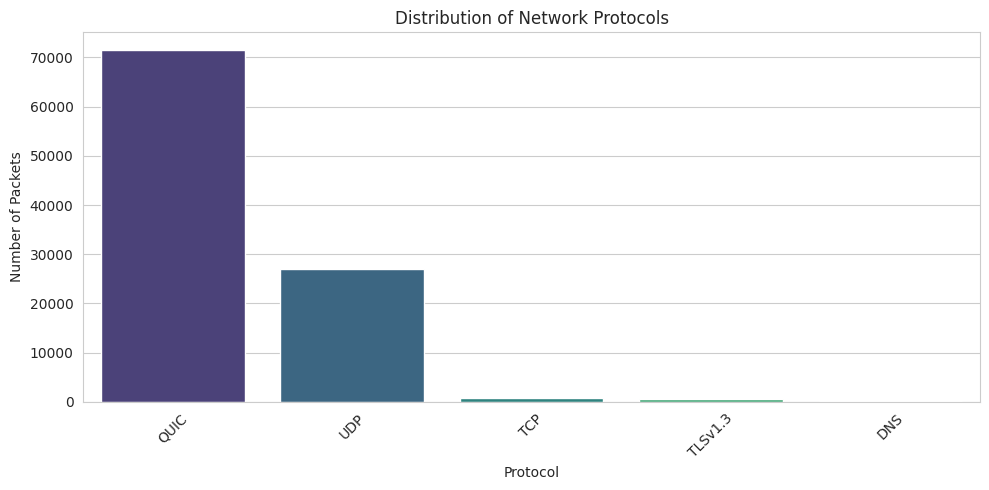

In [12]:
# This code creates a bar chart showing how many network packets belong to each protocol class.
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index,
    palette="viridis"
)

plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# This code displays summary statistics for packet length, which is an important numerical feature for protocol classification.
print("Packet Length Summary:")
display(df["Length"].describe())

Packet Length Summary:


,Length
count,100000.000000
mean,1048.712840
std,422.229808
min,40.000000
25%,981.000000
50%,1278.000000
75%,1278.000000
max,6205.000000


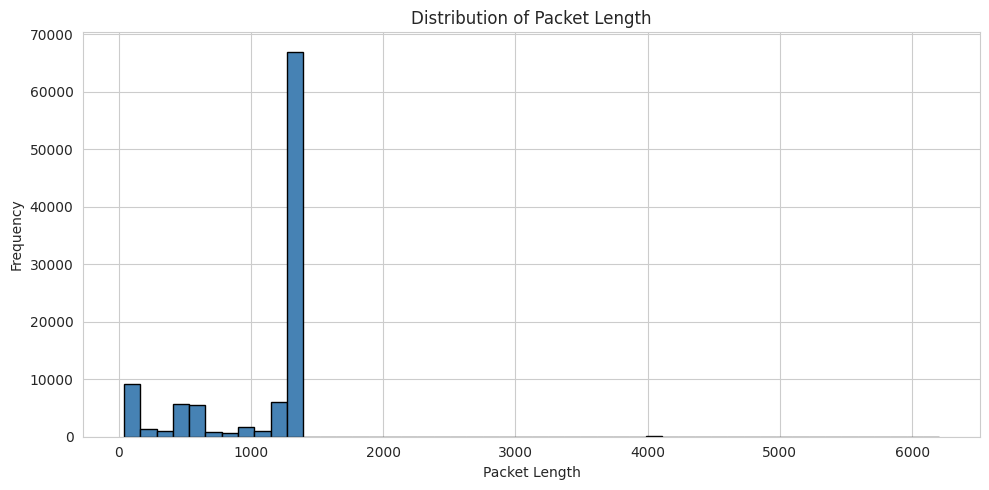

In [14]:
# This code creates a histogram to show how packet lengths are distributed in the dataset.
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50, color="steelblue", edgecolor="black")

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

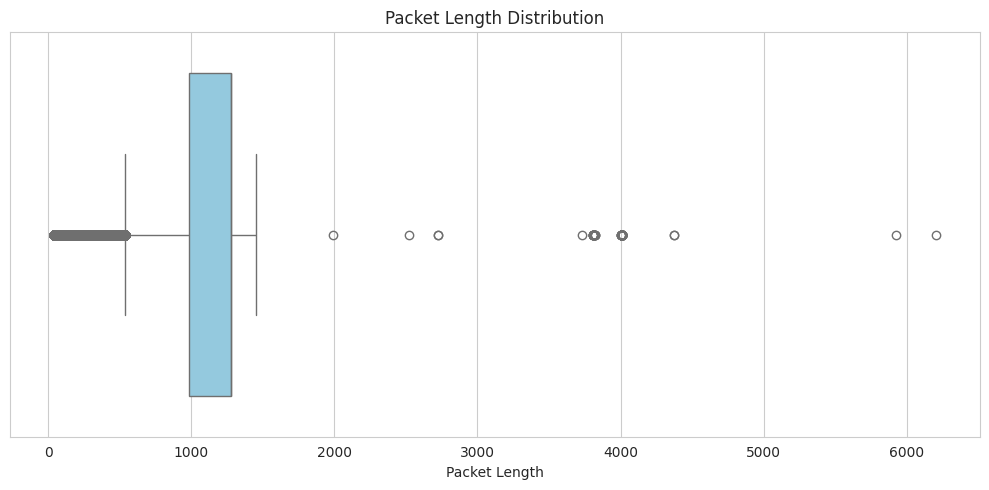

In [15]:
# This code creates a box plot to identify the spread and possible outliers in packet length values.
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"], color="skyblue")

plt.title("Packet Length Distribution")
plt.xlabel("Packet Length")
plt.tight_layout()
plt.show()

In [16]:
# This code extracts the hour, minute, and second from each packet timestamp to create useful ML input features.
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

print("Time feature preview:")
display(df[["Time", "Hour", "Minute", "Second"]].head())

Time feature preview:


,Time,Hour,Minute,Second
240264,2022-06-28 17:24:28.277637,17,24,28
249608,2022-06-28 17:25:32.346702,17,25,32
351294,2022-06-28 19:47:29.819227,19,47,29
328371,2022-06-28 19:42:57.264581,19,42,57
335134,2022-06-28 19:45:18.772737,19,45,18


In [17]:
# This code checks that the newly created time features do not contain missing values.
print("Missing values in the new time features:")
print(df[["Hour", "Minute", "Second"]].isnull().sum())

Missing values in the new time features:
Hour      0
Minute    0
Second    0
dtype: int64


In [18]:
# This code selects packet length and time-based values as input features, while Protocol is selected as the target to predict.
X = df[
    [
        "Length",
        "Hour",
        "Minute",
        "Second"
    ]
].copy()

y = df["Protocol"].copy()

print("Input features:")
display(X.head())

print("\nTarget values:")
display(y.head())

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Input features:


,Length,Hour,Minute,Second
240264,1278.0,17,24,28
249608,347.0,17,25,32
351294,1278.0,19,47,29
328371,1278.0,19,42,57
335134,1278.0,19,45,18



Target values:


,Protocol
240264,QUIC
249608,QUIC
351294,QUIC
328371,UDP
335134,QUIC



Feature dataset shape: (100000, 4)
Target dataset shape: (100000,)


In [19]:
# This code converts protocol names such as TCP, UDP, and QUIC into numerical labels required by machine-learning algorithms.
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Protocol classes:")
print(label_encoder.classes_)

print("\nFirst 20 encoded protocol values:")
print(y_encoded[:20])

Protocol classes:
['DNS' 'QUIC' 'TCP' 'TLSv1.3' 'UDP']

First 20 encoded protocol values:
[1 1 1 4 1 4 1 1 1 1 1 1 4 1 1 1 1 1 1 4]


In [20]:
# This code splits the dataset into 80 percent training data and 20 percent testing data while preserving protocol proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 80000
Testing samples: 20000


In [21]:
# This code standardizes feature values using only training data to prevent information leakage into the test data.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [22]:
# This code trains a Logistic Regression model using scaled training features and predicts protocol classes for the test data.
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(accuracy_lr * 100, 2), "%")

Logistic Regression Accuracy: 80.39 %


In [23]:
# This code trains a KNN model with five nearest neighbors and predicts protocol classes for the test data.
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", round(accuracy_knn * 100, 2), "%")

KNN Accuracy: 98.76 %


In [24]:
# This code trains a Decision Tree model using the original feature values and predicts protocols for the test data.
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(accuracy_dt * 100, 2), "%")

Decision Tree Accuracy: 99.33 %


In [25]:
# This code trains a Random Forest model with 100 decision trees and predicts protocols for the test data.
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")

Random Forest Accuracy: 99.61 %


In [26]:
# This code creates a table that compares the accuracy of all four machine-learning models.
results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "KNN",
            "Decision Tree",
            "Random Forest"
        ],
        "Accuracy": [
            accuracy_lr,
            accuracy_knn,
            accuracy_dt,
            accuracy_rf
        ]
    }
)

results["Accuracy (%)"] = (results["Accuracy"] * 100).round(2)

print("Model Comparison:")
display(results)

Model Comparison:


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.80390,80.39
1,KNN,0.98760,98.76
2,Decision Tree,0.99325,99.32
3,Random Forest,0.99615,99.62


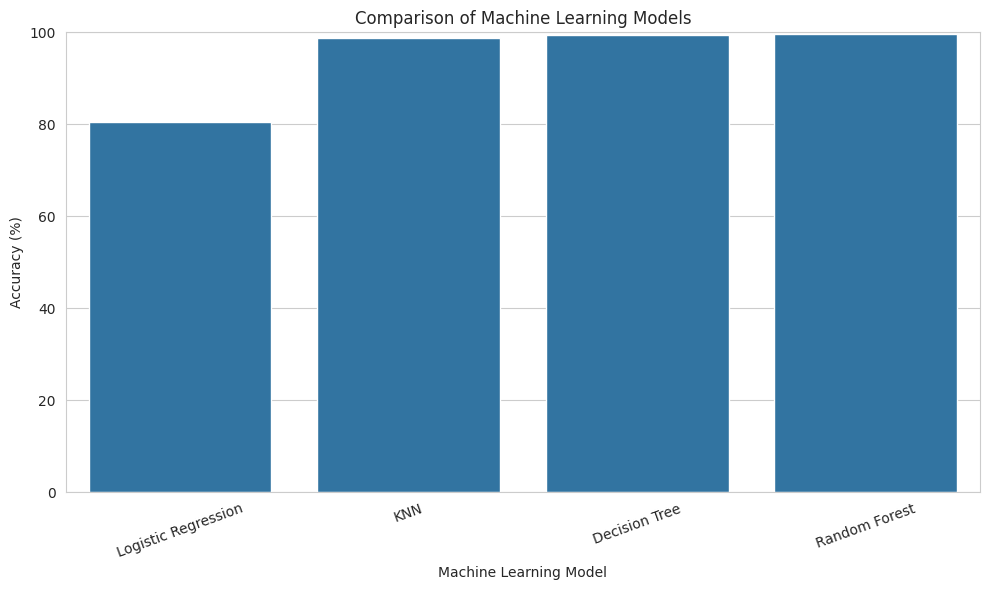

In [27]:
# This code creates a bar chart to visually compare the accuracy of all four machine-learning models.
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [28]:
# This code finds and displays the model with the highest test accuracy.
best_model = results.loc[results["Accuracy"].idxmax()]

print("Best Model:")
print(best_model)

Best Model:
Model           Random Forest
Accuracy              0.99615
Accuracy (%)            99.62
Name: 3, dtype: object


In [29]:
# This code evaluates Random Forest using precision, recall, F1-score, and support for every protocol class.
print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

         DNS       0.80      0.33      0.47        12
        QUIC       1.00      1.00      1.00     14308
         TCP       0.99      0.98      0.99       155
     TLSv1.3       0.91      0.83      0.87       107
         UDP       0.99      1.00      1.00      5418

    accuracy                           1.00     20000
   macro avg       0.94      0.83      0.86     20000
weighted avg       1.00      1.00      1.00     20000



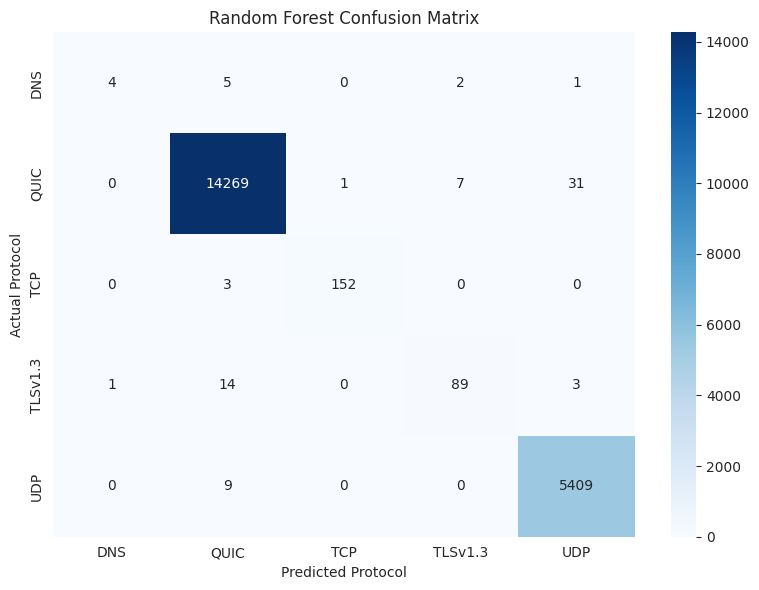

In [30]:
# This code creates a confusion matrix to compare actual protocol classes with Random Forest predictions.
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.tight_layout()
plt.show()

In [31]:
# This code shows how much each input feature contributed to the Random Forest protocol predictions.
feature_importance = pd.DataFrame(
    {
        "Feature": X.columns,
        "Importance": rf_model.feature_importances_
    }
).sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
2,Minute,0.771721
3,Second,0.087438
0,Length,0.082695
1,Hour,0.058146


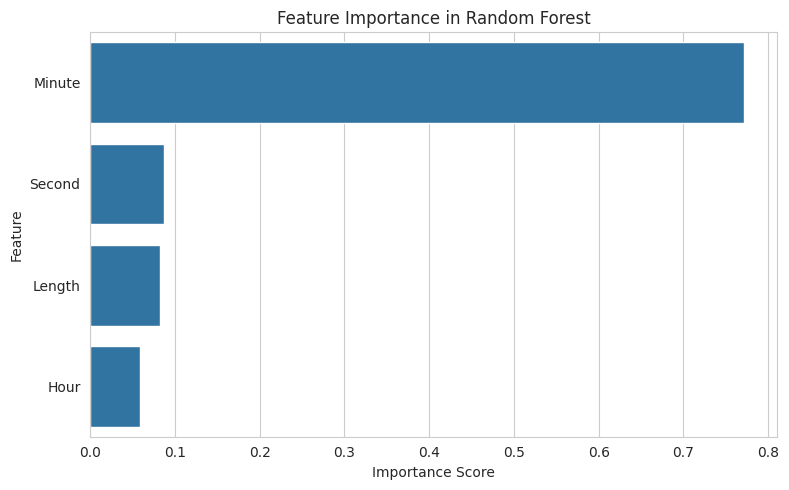

In [32]:
# This code creates a bar chart showing the importance of packet length and time-based features.
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

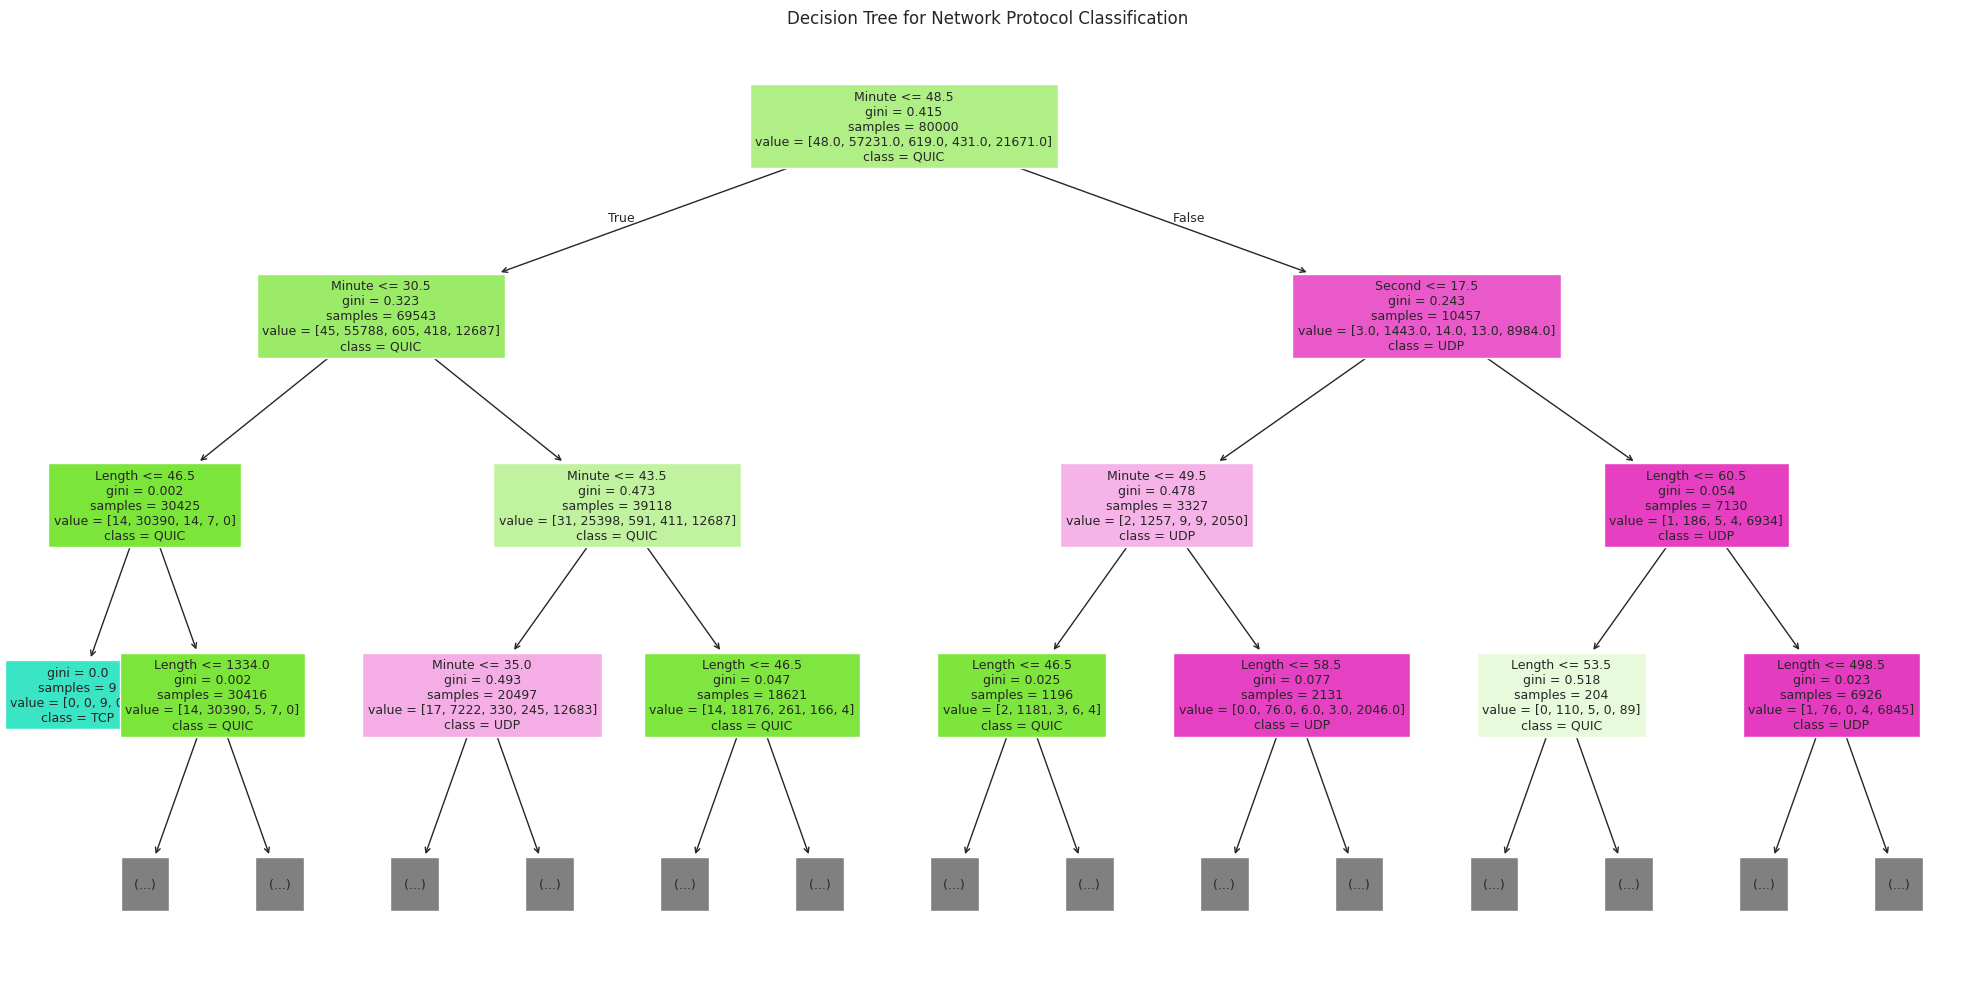

In [33]:
# This code displays the first three levels of the Decision Tree so that its decisions are easy to understand.
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree for Network Protocol Classification")
plt.tight_layout()
plt.show()

In [34]:
# This code creates one new packet example and uses Random Forest to predict its network protocol.
new_packet = pd.DataFrame(
    {
        "Length": [64],
        "Hour": [10],
        "Minute": [30],
        "Second": [15]
    }
)

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(prediction)

print("New Packet Details:")
display(new_packet)

print("Predicted Protocol:", predicted_protocol[0])

New Packet Details:


,Length,Hour,Minute,Second
0,64,10,30,15


Predicted Protocol: QUIC


In [35]:
# This code prints a final summary of model performance and identifies the best-performing model in the project.
print("FINAL PROJECT SUMMARY")
print("-" * 40)

for _, row in results.iterrows():
    print(f"{row['Model']}: {row['Accuracy (%)']:.2f}%")

print("\nBest Model:")
print(f"{best_model['Model']} with {best_model['Accuracy (%)']:.2f}% accuracy")

FINAL PROJECT SUMMARY
----------------------------------------
Logistic Regression: 80.39%
KNN: 98.76%
Decision Tree: 99.32%
Random Forest: 99.62%

Best Model:
Random Forest with 99.62% accuracy
